In [5]:
from google.colab import files

uploaded = files.upload()


Saving test_features.csv to test_features.csv


In [6]:
from google.colab import files

uploaded = files.upload()

Saving train_features.csv to train_features.csv


In [2]:
# Install the required machine learning and visualization libraries

!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost joblib

In [3]:
# ==========================================
# IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

# Machine Learning Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Data splitting and hyperparameter tuning
from sklearn.model_selection import train_test_split, RandomizedSearchCV

# Feature scaling
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)

# XGBoost
from xgboost import XGBClassifier

# Reproducibility
RANDOM_STATE = 42

# Target recall used for threshold optimization
TARGET_RECALL = 0.75

# Visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [7]:
# ==========================================
# LOAD PROCESSED DATASETS
# ==========================================

# These CSV files were generated during data preprocessing
# and contain the extracted URL features and target labels.

TRAIN_PATH = "train_features.csv"
TEST_PATH = "test_features.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Display dataset dimensions
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

# Display first five records
display(train_df.head())

Training Dataset Shape: (405755, 7)
Testing Dataset Shape: (101439, 7)


,URL_Length,Dot_Count,Hyphen_Count,Digit_Count,Special_Char_Count,Has_HTTPS,Label
0,78,2,0,7,8,0,0
1,44,2,4,1,9,0,1
2,50,2,0,13,6,0,0
3,40,1,4,0,7,0,0
4,31,1,0,1,4,0,0


In [8]:
# ==========================================
# DATASET INFORMATION
# ==========================================

print("========== TRAINING DATASET INFORMATION ==========")

train_df.info()

print("\n========== TESTING DATASET INFORMATION ==========")

test_df.info()

# Check missing values
print("\n========== MISSING VALUES ==========")

print(train_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Training Records:", train_df.duplicated().sum())
print("Duplicate Testing Records:", test_df.duplicated().sum())

========== TRAINING DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 405755 entries, 0 to 405754
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   URL_Length          405755 non-null  int64
 1   Dot_Count           405755 non-null  int64
 2   Hyphen_Count        405755 non-null  int64
 3   Digit_Count         405755 non-null  int64
 4   Special_Char_Count  405755 non-null  int64
 5   Has_HTTPS           405755 non-null  int64
 6   Label               405755 non-null  int64
dtypes: int64(7)
memory usage: 21.7 MB

========== TESTING DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101439 entries, 0 to 101438
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   URL_Length          101439 non-null  int64
 1   Dot_Count           101439 non-null  int64
 2   Hyphen_Cou

Training Class Distribution:
Label
Legitimate    314317
Phishing       91438
Name: count, dtype: int64


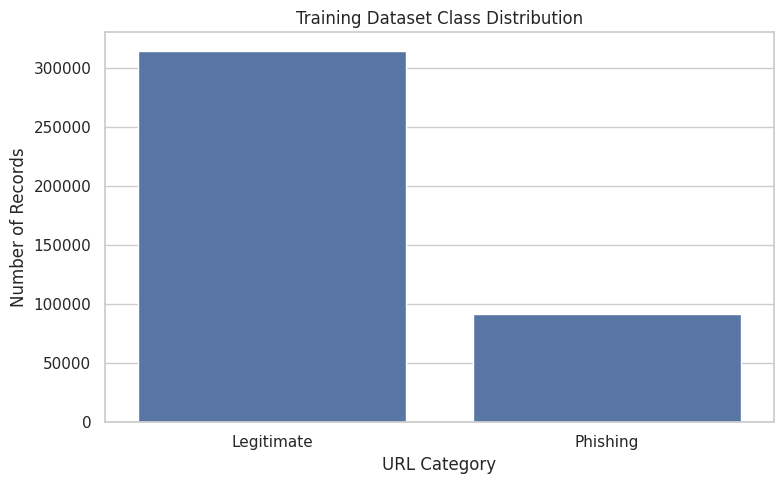

In [9]:
# ==========================================
# CLASS DISTRIBUTION ANALYSIS
# ==========================================

# Label 0 represents Legitimate URLs.
# Label 1 represents Phishing URLs.

class_counts = train_df["Label"].value_counts().sort_index()

class_names = ["Legitimate", "Phishing"]

print("Training Class Distribution:")
print(class_counts.rename(index={
    0: "Legitimate",
    1: "Phishing"
}))

# Visualize the class distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_names,
    y=[class_counts.get(0, 0), class_counts.get(1, 0)]
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("URL Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# FEATURE ANALYSIS
# ==========================================

FEATURE_COLUMNS = [
    "URL_Length",
    "Dot_Count",
    "Hyphen_Count",
    "Digit_Count",
    "Special_Char_Count",
    "Has_HTTPS"
]

# Verify that all expected features exist
print("Available Features:")

for feature in FEATURE_COLUMNS:
    print("-", feature)

# Statistical summary of extracted features
print("\n========== FEATURE STATISTICS ==========")

display(train_df[FEATURE_COLUMNS].describe())

# Compare average feature values across URL categories
print("\n========== FEATURE STATISTICS BY CLASS ==========")

display(
    train_df.groupby("Label")[FEATURE_COLUMNS].mean()
)

Available Features:
- URL_Length
- Dot_Count
- Hyphen_Count
- Digit_Count
- Special_Char_Count
- Has_HTTPS

========== FEATURE STATISTICS ==========


,URL_Length,Dot_Count,Hyphen_Count,Digit_Count,Special_Char_Count,Has_HTTPS
count,405755.000000,405755.000000,405755.000000,405755.000000,405755.000000,405755.000000
mean,51.486197,2.056125,1.195463,4.744471,7.069103,0.000007
std,43.003515,1.524729,2.495564,11.300512,5.669371,0.002719
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,1.000000,0.000000,0.000000,4.000000,0.000000
50%,41.000000,2.000000,0.000000,1.000000,6.000000,0.000000
75%,60.000000,2.000000,1.000000,6.000000,8.000000,0.000000
max,2307.000000,37.000000,42.000000,466.000000,222.000000,1.000000



========== FEATURE STATISTICS BY CLASS ==========


,URL_Length,Dot_Count,Hyphen_Count,Digit_Count,Special_Char_Count,Has_HTTPS
Label,,,,,,
0,45.765301,1.780066,1.333405,3.131991,6.475491,0.000000
1,71.151709,3.005074,0.721287,10.287353,9.109637,0.000033


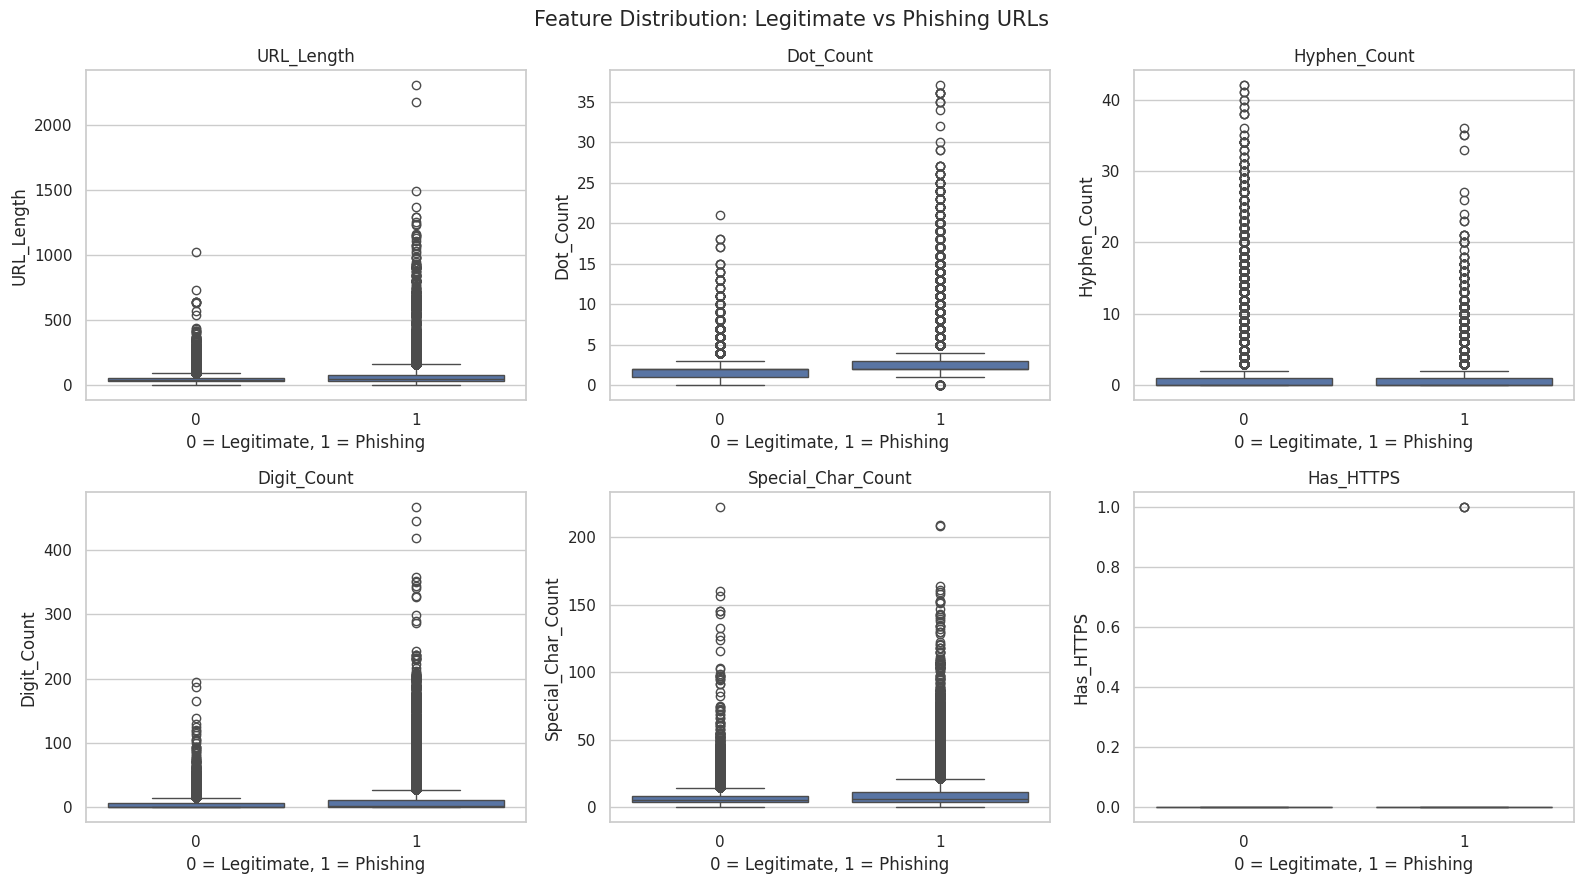

In [11]:
# ==========================================
# FEATURE DISTRIBUTION BY URL CATEGORY
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), FEATURE_COLUMNS):

    sns.boxplot(
        data=train_df,
        x="Label",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("0 = Legitimate, 1 = Phishing")

plt.suptitle(
    "Feature Distribution: Legitimate vs Phishing URLs",
    fontsize=15
)

plt.tight_layout()
plt.show()

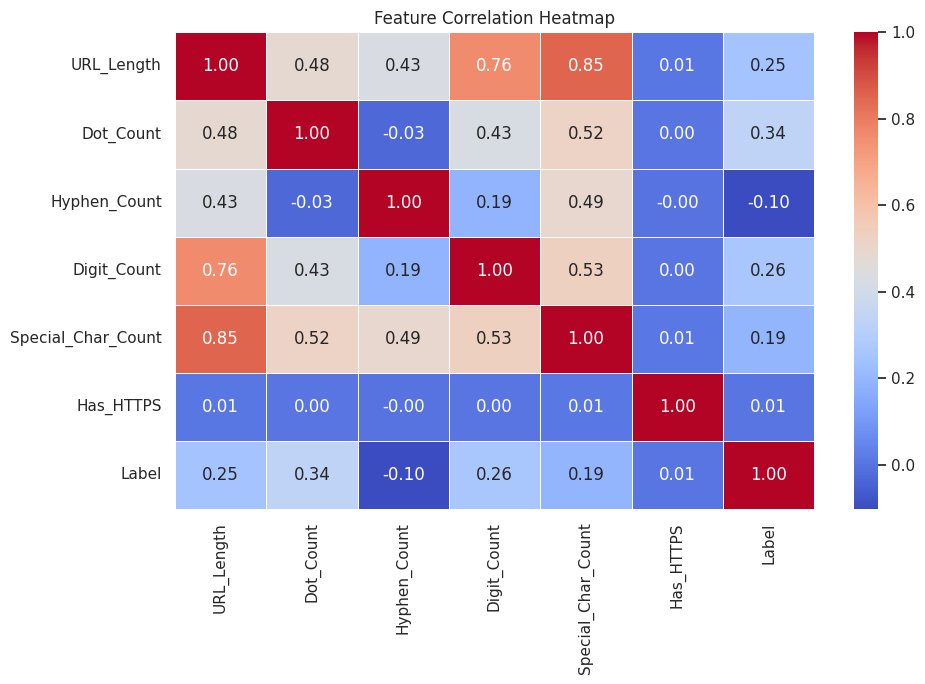

In [12]:
# ==========================================
# FEATURE CORRELATION ANALYSIS
# ==========================================

# Calculate correlation between numerical features
correlation_matrix = train_df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [13]:
# ==========================================
# FEATURE AND TARGET SEPARATION
# ==========================================

# Separate input features and target labels

X_train = train_df.drop("Label", axis=1)
y_train = train_df["Label"]

X_test = test_df.drop("Label", axis=1)
y_test = test_df["Label"]

# Split training data into sub-training and validation sets.
# The test dataset remains separate for final evaluation.

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Original Training Data:", X_train.shape)
print("Sub-training Data:", X_subtrain.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nTraining and validation split completed.")

Original Training Data: (405755, 6)
Sub-training Data: (324604, 6)
Validation Data: (81151, 6)
Testing Data: (101439, 6)

Training and validation split completed.


In [14]:
# ==========================================
# HELPER FUNCTION: SELECT RECALL THRESHOLD
# ==========================================

def select_recall_threshold(model, X_val, y_val, model_name):

    # Obtain phishing probabilities for validation samples
    probabilities = model.predict_proba(X_val)[:, 1]

    # Calculate precision and recall at different thresholds
    precisions, recalls, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    # Identify thresholds that satisfy the target recall
    valid_indices = [
        i for i in range(len(thresholds))
        if recalls[i] >= TARGET_RECALL
    ]

    if not valid_indices:
        raise ValueError(
            f"{model_name} could not achieve target validation recall."
        )

    # Select the threshold with the highest precision.
    # If precision is equal, prefer the higher threshold.
    best_index = max(
        valid_indices,
        key=lambda i: (precisions[i], thresholds[i])
    )

    best_threshold = thresholds[best_index]

    print(f"\n{model_name} Selected Threshold: {best_threshold:.6f}")
    print(f"Validation Precision: {precisions[best_index]:.4f}")
    print(f"Validation Recall: {recalls[best_index]:.4f}")

    return best_threshold, probabilities

In [15]:
# ==========================================
# DECISION TREE CLASSIFIER
# ==========================================

# Train Decision Tree on sub-training data

dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

dt_model.fit(X_subtrain, y_subtrain)

# Select a threshold using validation data
dt_threshold, dt_val_probabilities = select_recall_threshold(
    dt_model,
    X_val,
    y_val,
    "DECISION TREE"
)

# Retrain the final Decision Tree on the complete training dataset

dt_final = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

dt_final.fit(X_train, y_train)

print("\nDecision Tree training completed.")


DECISION TREE Selected Threshold: 0.179104
Validation Precision: 0.4753
Validation Recall: 0.7501

Decision Tree training completed.


In [16]:
# ==========================================
# K-NEAREST NEIGHBORS CLASSIFIER
# ==========================================

# KNN uses StandardScaler because distance-based
# algorithms can be affected by differences in feature scales.

def create_knn():

    return Pipeline([
        ("scaler", StandardScaler()),

        ("knn", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            algorithm="kd_tree",
            leaf_size=40,
            n_jobs=-1
        ))
    ])


# Train KNN on sub-training data
knn_model = create_knn()

knn_model.fit(X_subtrain, y_subtrain)

# Optimize classification threshold using validation data
knn_threshold, knn_val_probabilities = select_recall_threshold(
    knn_model,
    X_val,
    y_val,
    "KNN"
)

# Retrain final KNN using complete training data
knn_final = create_knn()

knn_final.fit(X_train, y_train)

print("\nKNN training completed.")


KNN Selected Threshold: 0.200000
Validation Precision: 0.3973
Validation Recall: 0.8095

KNN training completed.


In [17]:
# ==========================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ==========================================

# Initialize Random Forest
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Hyperparameter search space
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
    "class_weight": ["balanced"]
}

# RandomizedSearchCV evaluates different parameter combinations
# using cross-validation and average precision scoring.

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=4,
    cv=2,
    scoring="average_precision",
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=2
)

# Perform hyperparameter tuning on sub-training data
random_search.fit(X_subtrain, y_subtrain)

# Retrieve the best model
rf_final = random_search.best_estimator_

print("\nBest Random Forest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Average Precision:")
print(random_search.best_score_)

# Select threshold using validation data
rf_threshold, rf_val_probabilities = select_recall_threshold(
    rf_final,
    X_val,
    y_val,
    "RANDOM FOREST"
)

# Retrain selected Random Forest on complete training data
rf_final.fit(X_train, y_train)

print("\nRandom Forest training completed.")

Fitting 2 folds for each of 4 candidates, totalling 8 fits

Best Random Forest Parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}

Best Cross-Validation Average Precision:
0.7441597339399624

RANDOM FOREST Selected Threshold: 0.448962
Validation Precision: 0.5275
Validation Recall: 0.7501

Random Forest training completed.


In [18]:
# ==========================================
# XGBOOST CLASSIFIER
# ==========================================

# Calculate class imbalance ratio
scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

print("Scale Pos Weight:", scale_pos_weight)

# Initialize XGBoost with the same configuration as train.py
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=2
)

# Train using sub-training data
xgb_model.fit(X_subtrain, y_subtrain)

# Select threshold using validation data
xgb_threshold, xgb_val_probabilities = select_recall_threshold(
    xgb_model,
    X_val,
    y_val,
    "XGBOOST"
)

# Retrain using complete training data
xgb_model.fit(X_train, y_train)

print("\nXGBoost training completed.")

Scale Pos Weight: 3.43748769658129

XGBOOST Selected Threshold: 0.437103
Validation Precision: 0.4851
Validation Recall: 0.7502

XGBoost training completed.


In [19]:
# ==========================================
# COLLECT TRAINED MODELS AND THRESHOLDS
# ==========================================

models = {
    "Decision Tree": (dt_final, dt_threshold),
    "KNN": (knn_final, knn_threshold),
    "Random Forest": (rf_final, rf_threshold),
    "XGBoost": (xgb_model, xgb_threshold)
}

print("All four models are ready for evaluation.")

for model_name in models:
    print("-", model_name)

All four models are ready for evaluation.
- Decision Tree
- KNN
- Random Forest
- XGBoost


In [20]:
# ==========================================
# FINAL MODEL EVALUATION
# ==========================================

results = []
predictions = {}
test_probabilities = {}

for model_name, (model, threshold) in models.items():

    # Generate phishing probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Apply the selected validation threshold
    y_pred = (probabilities >= threshold).astype(int)

    # Store predictions and probabilities for visualization
    predictions[model_name] = y_pred
    test_probabilities[model_name] = probabilities

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    average_precision = average_precision_score(
        y_test,
        probabilities
    )

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Average Precision": average_precision,
        "Threshold": threshold
    })


# Create final comparison dataframe
results_df = pd.DataFrame(results)

print("========== MODEL PERFORMANCE COMPARISON ==========")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Average Precision": "{:.4f}",
        "Threshold": "{:.4f}"
    })
)

========== MODEL PERFORMANCE COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1-Score,Average Precision,Threshold
0,Decision Tree,0.7612,0.4810,0.7534,0.5872,0.6702,0.1791
1,KNN,0.6625,0.3832,0.8163,0.5216,0.6472,0.2000
2,Random Forest,0.7926,0.5282,0.7464,0.6186,0.7546,0.4490
3,XGBoost,0.7591,0.4779,0.7472,0.5829,0.7179,0.4371


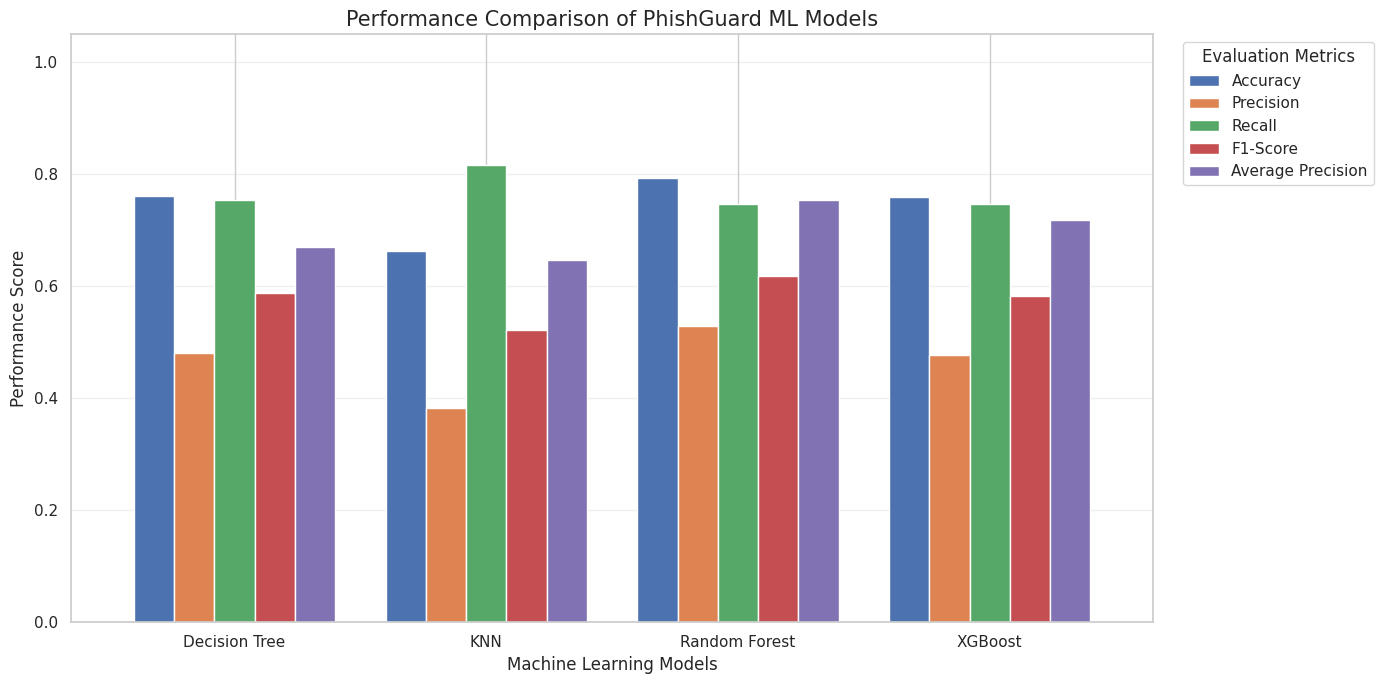

In [21]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Average Precision"
]

# Prepare data for visualization
comparison_data = results_df.set_index("Model")[metrics]

# Generate grouped bar chart
comparison_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Performance Comparison of PhishGuard ML Models",
    fontsize=15
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

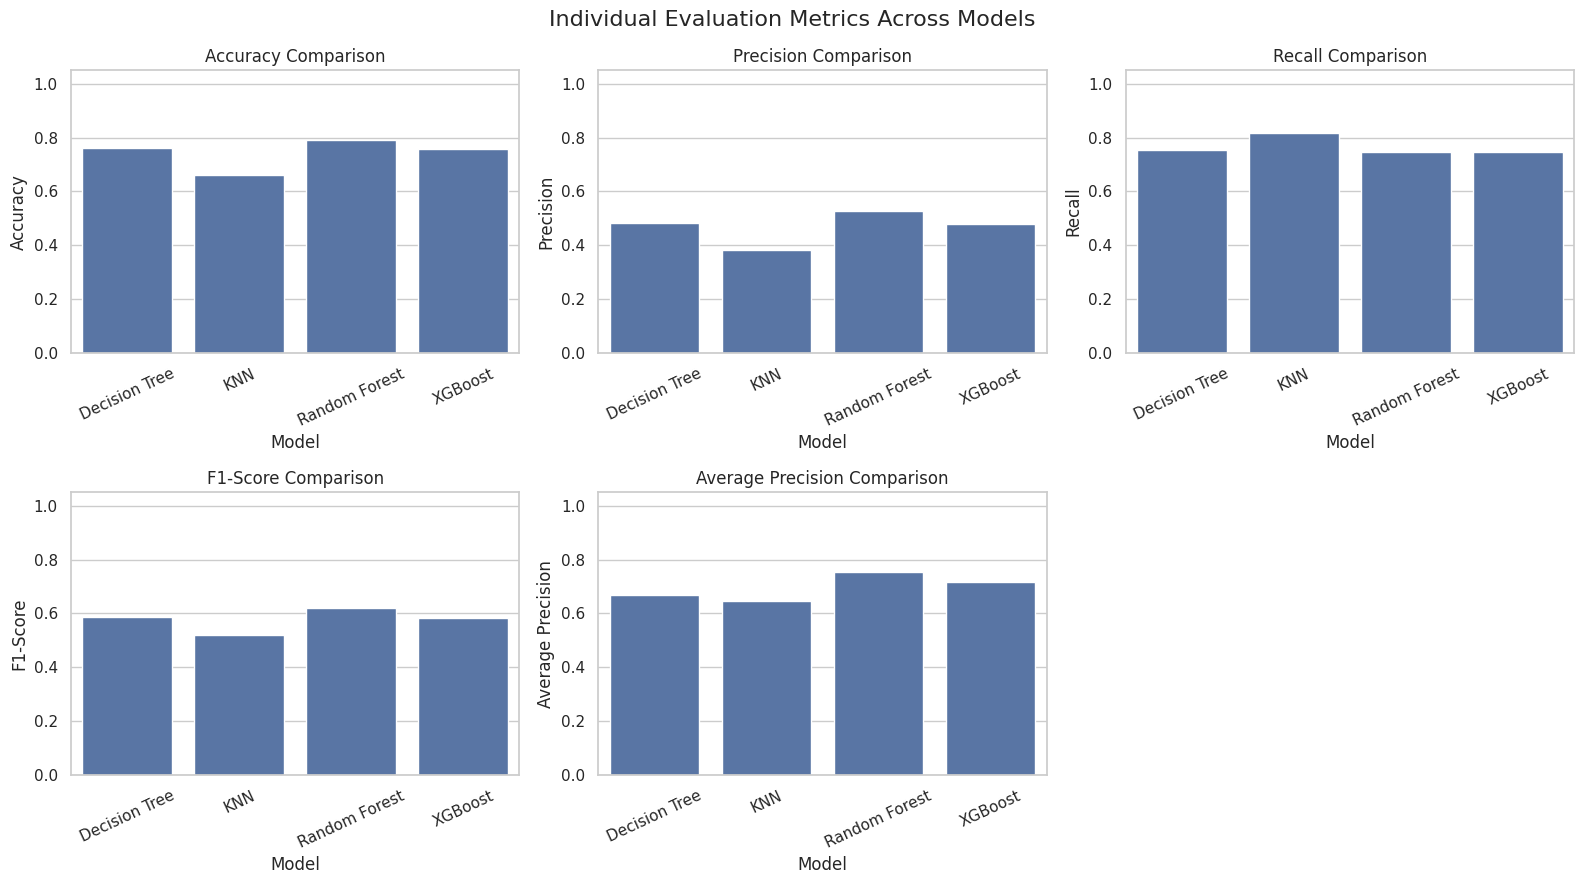

In [22]:
# ==========================================
# INDIVIDUAL METRIC COMPARISON
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25)

# Remove the unused sixth subplot
fig.delaxes(axes.flatten()[5])

plt.suptitle(
    "Individual Evaluation Metrics Across Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

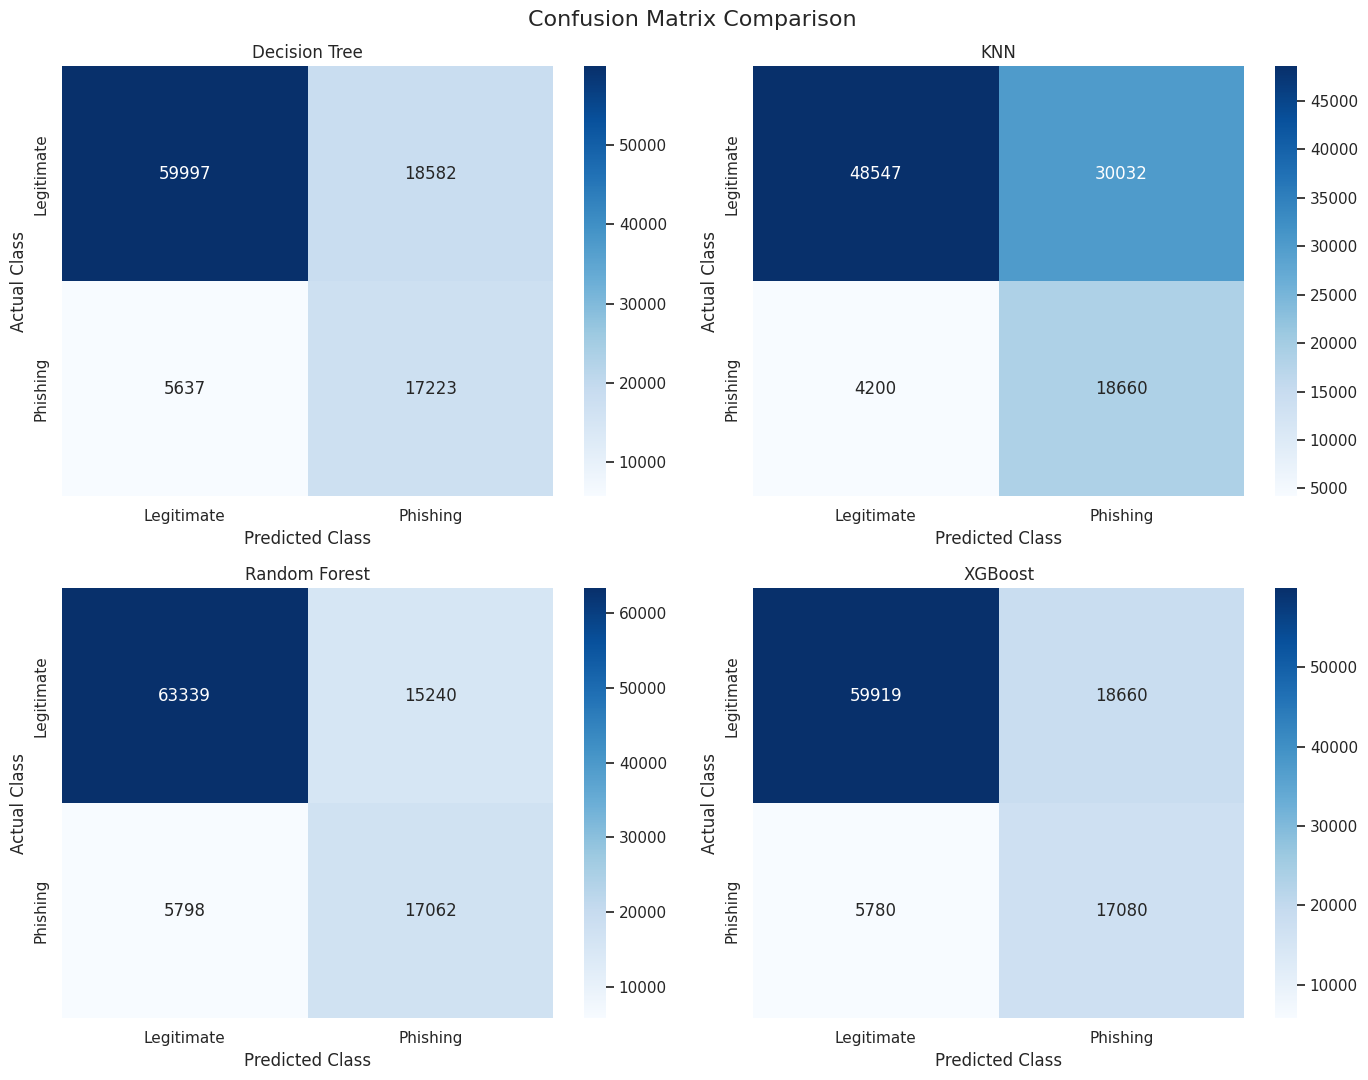

In [23]:
# ==========================================
# CONFUSION MATRIX COMPARISON
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (model_name, y_pred) in zip(
    axes.flatten(),
    predictions.items()
):

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Display confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [24]:
# ==========================================
# CLASSIFICATION REPORTS FOR ALL MODELS
# ==========================================

for model_name, y_pred in predictions.items():

    print("\n" + "=" * 55)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Legitimate", "Phishing"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.91      0.76      0.83     78579
    Phishing       0.48      0.75      0.59     22860

    accuracy                           0.76    101439
   macro avg       0.70      0.76      0.71    101439
weighted avg       0.82      0.76      0.78    101439


CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

  Legitimate       0.92      0.62      0.74     78579
    Phishing       0.38      0.82      0.52     22860

    accuracy                           0.66    101439
   macro avg       0.65      0.72      0.63    101439
weighted avg       0.80      0.66      0.69    101439


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

  Legitimate       0.92      0.81      0.86     78579
    Phishing       0.53      0.75      0.62     22860

    accuracy                           0.79    101439
   macro avg       0.72 

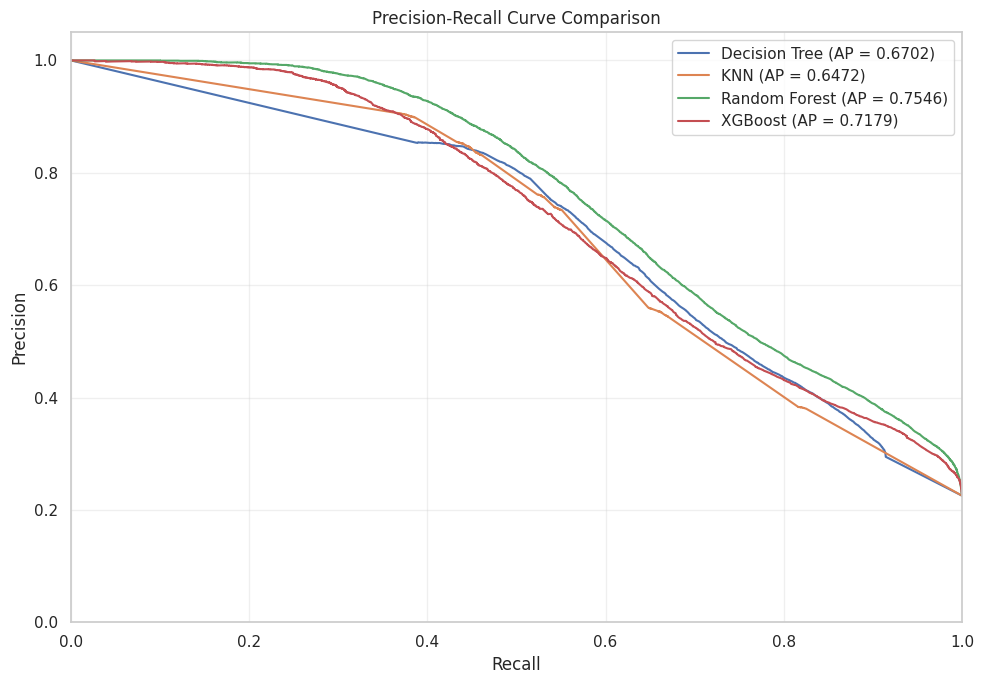

In [25]:
# ==========================================
# PRECISION-RECALL CURVE COMPARISON
# ==========================================

plt.figure(figsize=(10, 7))

for model_name, probabilities in test_probabilities.items():

    # Calculate precision and recall at different thresholds
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    # Calculate Average Precision
    ap_score = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{model_name} (AP = {ap_score:.4f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

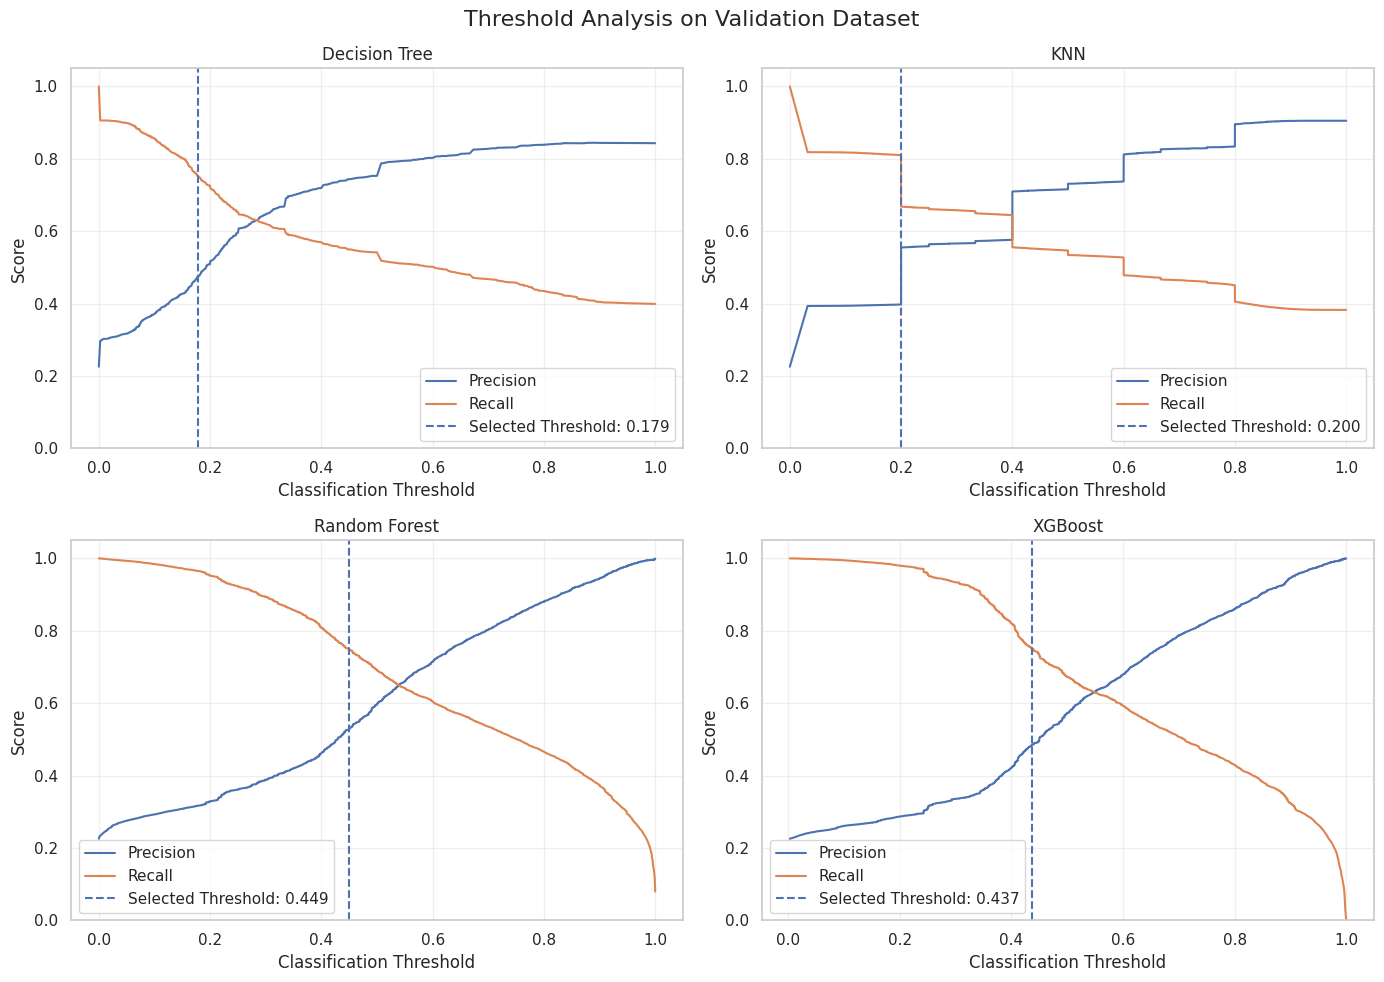

In [26]:
# ==========================================
# PRECISION AND RECALL VS THRESHOLD
# ==========================================

validation_probabilities = {
    "Decision Tree": (dt_val_probabilities, dt_threshold),
    "KNN": (knn_val_probabilities, knn_threshold),
    "Random Forest": (rf_val_probabilities, rf_threshold),
    "XGBoost": (xgb_val_probabilities, xgb_threshold)
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (model_name, (probabilities, selected_threshold)) in zip(
    axes.flatten(),
    validation_probabilities.items()
):

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_val, probabilities)
    )

    # Thresholds has one fewer element than precision/recall
    ax.plot(
        thresholds,
        precision_values[:-1],
        label="Precision"
    )

    ax.plot(
        thresholds,
        recall_values[:-1],
        label="Recall"
    )

    # Mark the selected threshold
    ax.axvline(
        selected_threshold,
        linestyle="--",
        label=f"Selected Threshold: {selected_threshold:.3f}"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)

    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Threshold Analysis on Validation Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

,Feature,Importance
3,Digit_Count,0.273125
0,URL_Length,0.238192
1,Dot_Count,0.189047
4,Special_Char_Count,0.173058
2,Hyphen_Count,0.126577
5,Has_HTTPS,0.000000


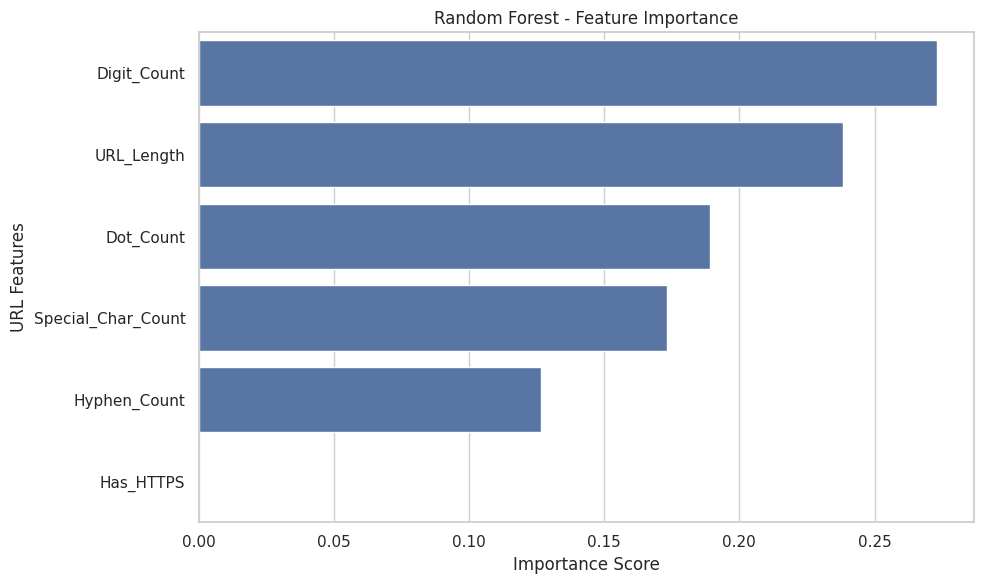

In [27]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

# Feature importance indicates how much each feature
# contributes to the Random Forest's decision process.

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_final.feature_importances_
})

# Sort features from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("URL Features")

plt.tight_layout()
plt.show()

========== FINAL RANDOM FOREST RESULTS ==========
              precision    recall  f1-score   support

  Legitimate       0.92      0.81      0.86     78579
    Phishing       0.53      0.75      0.62     22860

    accuracy                           0.79    101439
   macro avg       0.72      0.78      0.74    101439
weighted avg       0.83      0.79      0.80    101439



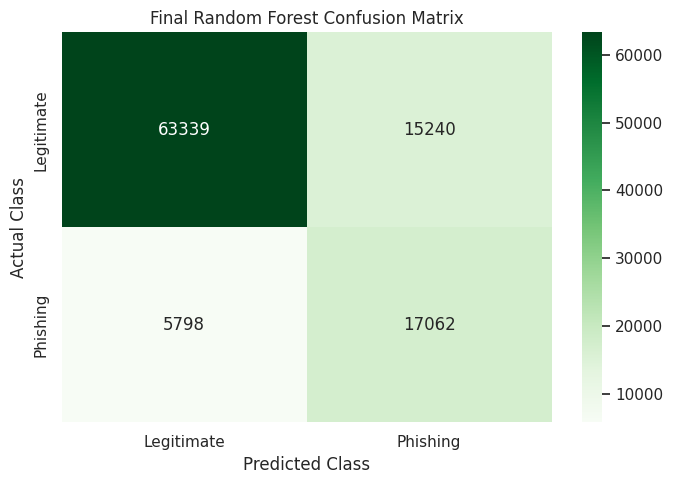

Selected Threshold: 0.44896186982842456
Best Hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}


In [28]:
# ==========================================
# FINAL SELECTED MODEL: RANDOM FOREST
# ==========================================

# Random Forest is the selected final model in the
# current PhishGuard ML implementation.

rf_predictions = predictions["Random Forest"]

print("========== FINAL RANDOM FOREST RESULTS ==========")

print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

# Display its confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Selected Threshold:", rf_threshold)
print("Best Hyperparameters:", random_search.best_params_)

In [29]:
# ==========================================
# FINAL MODEL COMPARISON SUMMARY
# ==========================================

# Rank models by F1-score for reporting purposes.
# This ranking is descriptive, not an automatic
# replacement for the project's final model decision.

ranked_models = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

ranked_models.insert(
    0,
    "F1 Rank",
    range(1, len(ranked_models) + 1)
)

print("========== FINAL MODEL RANKING BY F1-SCORE ==========")

display(ranked_models)

print("\n========== PROJECT MODEL SELECTION ==========")

print("Selected Model: Tuned Random Forest")
print(f"Selected Threshold: {rf_threshold:.6f}")

print("\nSelection should be interpreted using:")
print("- Precision")
print("- Recall")
print("- F1-Score")
print("- Average Precision")
print("- False Negative and False Positive counts")

========== FINAL MODEL RANKING BY F1-SCORE ==========


,F1 Rank,Model,Accuracy,Precision,Recall,F1-Score,Average Precision,Threshold
0,1,Random Forest,0.792604,0.528203,0.746369,0.618614,0.754631,0.448962
1,2,Decision Tree,0.761246,0.481022,0.753412,0.587164,0.670194,0.179104
2,3,XGBoost,0.759067,0.477896,0.747157,0.582935,0.717908,0.437103
3,4,KNN,0.662536,0.383225,0.816273,0.521579,0.647231,0.200000



========== PROJECT MODEL SELECTION ==========
Selected Model: Tuned Random Forest
Selected Threshold: 0.448962

Selection should be interpreted using:
- Precision
- Recall
- F1-Score
- Average Precision
- False Negative and False Positive counts


In [30]:
# ==========================================
# EXPORT EXPERIMENT RESULTS
# ==========================================

# Save model comparison results
results_df.to_csv(
    "PhishGuard_Model_Comparison.csv",
    index=False
)

# Save feature importance results
feature_importance.to_csv(
    "PhishGuard_Feature_Importance.csv",
    index=False
)

# Save the best Random Forest hyperparameters
best_parameters_df = pd.DataFrame(
    list(random_search.best_params_.items()),
    columns=["Parameter", "Value"]
)

best_parameters_df.to_csv(
    "PhishGuard_RF_Best_Parameters.csv",
    index=False
)

print("All experiment results exported successfully.")

All experiment results exported successfully.


In [31]:
# ==========================================
# DOWNLOAD EXPERIMENT RESULTS
# ==========================================

from google.colab import files

files.download("PhishGuard_Model_Comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from google.colab import files
files.download("PhishGuard_Feature_Importance.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from google.colab import files
files.download("PhishGuard_RF_Best_Parameters.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# ==========================================
# COMBINE ALL EXPERIMENT RESULTS INTO ZIP
# ==========================================

import zipfile
from google.colab import files

# List of generated CSV files
result_files = [
    "PhishGuard_Model_Comparison.csv",
    "PhishGuard_Feature_Importance.csv",
    "PhishGuard_RF_Best_Parameters.csv"
]

# Create ZIP archive
with zipfile.ZipFile(
    "PhishGuard_Experiment_Results.zip",
    "w"
) as zip_file:

    for file_name in result_files:

        zip_file.write(file_name)

        print("Added:", file_name)

print("\nZIP file created successfully!")

# Download all results together
files.download("PhishGuard_Experiment_Results.zip")

Added: PhishGuard_Model_Comparison.csv
Added: PhishGuard_Feature_Importance.csv
Added: PhishGuard_RF_Best_Parameters.csv

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>